# Choosing barriers for a mean-reverting strategy

A centered Ornstein-Uhlenbeck process moves toward zero while receiving continuous random shocks:

$$
dY_t=-\theta Y_t\,dt+\sigma\,dW_t,
\qquad
\operatorname{Var}_{\infty}(Y_t)=\frac{\sigma^2}{2\theta},
\qquad
h_{1/2}=\frac{\log 2}{\theta}.
$$

Here, $Y_t$ is the deviation from its long-run mean, $\theta>0$ is the speed of mean reversion, $\sigma>0$ is the shock scale per square-root time unit, $W_t$ is standard Brownian motion, $\operatorname{Var}_{\infty}(Y_t)$ is the stationary variance, and $h_{1/2}$ is the half-life of a deviation.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display

def compact_float_format(number_format=None):

    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value

def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch('[+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?', rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return '0'
    if ('.' in rendered or 'e' in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered

def compact_numeric_text(text):
    pattern = '(?<![0-9.eE])([+-]?(?:[0-9]+(?:\\.[0-9]*)?|\\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])'
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)

def compact_table_latex(latex):
    return compact_numeric_text(latex)

def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + '</div>'

def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)
from pathlib import Path
import math
import sys
import time
import warnings
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats as ss
from IPython.display import Image
warnings.filterwarnings('ignore')
ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
DATA_URL = 'https://fred.stlouisfed.org/graph/fredgraph.csv?id=SP500&cosd=2014-01-02&coed=2025-12-31'
DATA_DIR = ROOT / 'data' / 'public' / 'fred'
DATA_PATH = ensure_dataset(ROOT, 'fred_sp500')
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
raw = pd.read_csv(DATA_PATH)
raw['observation_date'] = pd.to_datetime(raw['observation_date'])
prices = raw.set_index('observation_date')['SP500'].dropna().astype(float).sort_index()
simple_returns = prices.pct_change()
log_returns = np.log(prices).diff()
FIGURES = ROOT / 'outputs' / 'figures' / '22_position_sizing'
TABLES = ROOT / 'outputs' / 'tables' / '22_position_sizing'
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
palette = {'background': '#111827', 'axes': '#111827', 'text': '#E5E7EB', 'cyan': '#38BDF8', 'amber': '#FBBF24', 'green': '#34D399', 'rose': '#FB7185', 'violet': '#C084FC', 'grid': '#374151', 'muted': '#94A3B8'}
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': palette['background'], 'axes.facecolor': palette['axes'], 'axes.edgecolor': palette['text'], 'axes.labelcolor': palette['text'], 'axes.titlecolor': palette['text'], 'xtick.color': palette['text'], 'ytick.color': palette['text'], 'text.color': palette['text'], 'grid.color': palette['grid'], 'grid.linestyle': ':', 'legend.facecolor': palette['axes'], 'legend.edgecolor': palette['grid'], 'savefig.facecolor': palette['background']})

def save_table(frame, stem, caption, label, float_format='%.6f', fit=True):
    frame.to_csv(TABLES / f'{stem}.csv', index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position='H'))
    if fit:
        latex = latex.replace('\\begin{tabular}', '\\begin{adjustbox}{max width=\\textwidth}\\begin{tabular}', 1).replace('\\end{tabular}', '\\end{tabular}\\end{adjustbox}', 1)
    else:
        latex = latex.replace('\\begin{tabular}', '\\centering\n' + '\\begin{tabular}', 1)
    latex = latex.replace('nan', 'Not available').replace('NaN', 'Not available').replace('inf', 'No finite value')
    (TABLES / f'{stem}.tex').write_text(latex, encoding='utf-8')

def save_figure(figure, stem):
    figure.savefig(FIGURES / f'{stem}.png', bbox_inches='tight', dpi=300)
    figure.savefig(FIGURES / f'{stem}.pdf', bbox_inches='tight')
    display(Image(filename=str(FIGURES / f'{stem}.png')))
    plt.close(figure)
data_provenance = pd.DataFrame({'Field': ['Series', 'Provider', 'Source', 'Retrieved', 'First price', 'Last price', 'Price observations'], 'Value': ['S&P 500', 'Federal Reserve Bank of St. Louis', DATA_URL, '2026-09-28', str(prices.index.min().date()), str(prices.index.max().date()), len(prices)]})
from RiskLabAI.backtest.ou_trading_rules import fit_ornstein_uhlenbeck, hit_upper_probability, mean_exit_time, optimal_ou_trading_rule, ou_rule_metrics, stationary_std, theta_from_half_life
log_prices = np.log(prices)
public_deviation = (log_prices - log_prices.rolling(60).mean()).dropna()
standardized_deviation = (public_deviation - public_deviation.mean()) / public_deviation.std(ddof=1)
public_fit = fit_ornstein_uhlenbeck(standardized_deviation.to_numpy(), dt=1.0)

def simulate_ou(theta, sigma, n_paths, n_steps, dt, rng, y_start=0.0):
    rho = np.exp(-theta * dt)
    innovation_scale = sigma * np.sqrt((1.0 - rho ** 2) / (2.0 * theta))
    state = np.full(n_paths, float(y_start))
    paths = np.empty((n_paths, n_steps))
    for location in range(n_steps):
        state = rho * state + innovation_scale * rng.standard_normal(n_paths)
        paths[:, location] = state
    return paths

def monte_carlo_return_rate(paths, entry_gap, profit_take, stop_loss, cost, dt):
    starting_value = -entry_gap
    upper = starting_value + profit_take
    lower = starting_value - stop_loss
    hits_upper = paths >= upper
    hits = hits_upper | (paths <= lower)
    any_hit = hits.any(axis=1)
    first_hit = np.argmax(hits, axis=1)
    profitable = hits_upper[np.arange(len(first_hit)), first_hit][any_hit]
    gains = np.where(profitable, profit_take, -stop_loss)
    holding_times = (first_hit[any_hit] + 1) * dt
    return (gains.mean() - cost) / holding_times.mean() if gains.size else -np.inf
plt.rcParams.update({'font.family': 'Times New Roman', 'font.size': 11.5, 'figure.facecolor': '#111827', 'axes.facecolor': '#111827', 'axes.edgecolor': '#94A3B8', 'axes.labelcolor': '#E5E7EB', 'axes.titlecolor': '#E5E7EB', 'axes.titleweight': 'bold', 'xtick.color': '#94A3B8', 'ytick.color': '#94A3B8', 'text.color': '#E5E7EB', 'grid.color': '#374151', 'grid.linestyle': ':', 'grid.linewidth': 0.8, 'legend.facecolor': '#111827', 'legend.edgecolor': '#374151', 'legend.framealpha': 0.96, 'savefig.facecolor': '#111827', 'savefig.transparent': False, 'savefig.dpi': 300, 'pdf.fonttype': 42, 'ps.fonttype': 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == '3.2.0'


## Public Mean-Reverting Deviation

Discrete daily observations are fitted through a first-order relation:

$$
Y_t=a+\rho Y_{t-1}+\varepsilon_t,
\qquad
\widehat\theta=-\log(\widehat\rho),
\qquad
\widehat\mu=\frac{\widehat a}{1-\widehat\rho}.
$$

Here, $Y_t$ is the standardized log-price deviation on day $t$, $a$ is the fitted intercept, $\rho\in(0,1)$ is the one-day persistence, $\varepsilon_t$ is the fitted innovation, $\widehat\theta$ is the estimated continuous mean-reversion speed for a one-day step, and $\widehat\mu$ is the estimated long-run mean.

,Field,Value
0,Series,S&P 500
1,Provider,Federal Reserve Bank of St. Louis
2,Source,https://fred.stlouisfed.org/graph/fredgraph.cs...
3,First deviation,2016-12-19
4,Last deviation,2025-12-31
5,Deviation definition,"Log price minus its sixty-day rolling mean, th..."


,Quantity,Value
0,Public observations,2330
1,Deviation observations,2271
2,Rolling mean length,60
3,Persistence,0.961987
4,Mean-reversion speed,0.038754
5,Shock scale,0.278229
6,Long-run mean,-0.008460
7,Half-life in trading days,17.885895
8,Stationary standard deviation,0.999378
9,One-step fit R-squared,0.925566


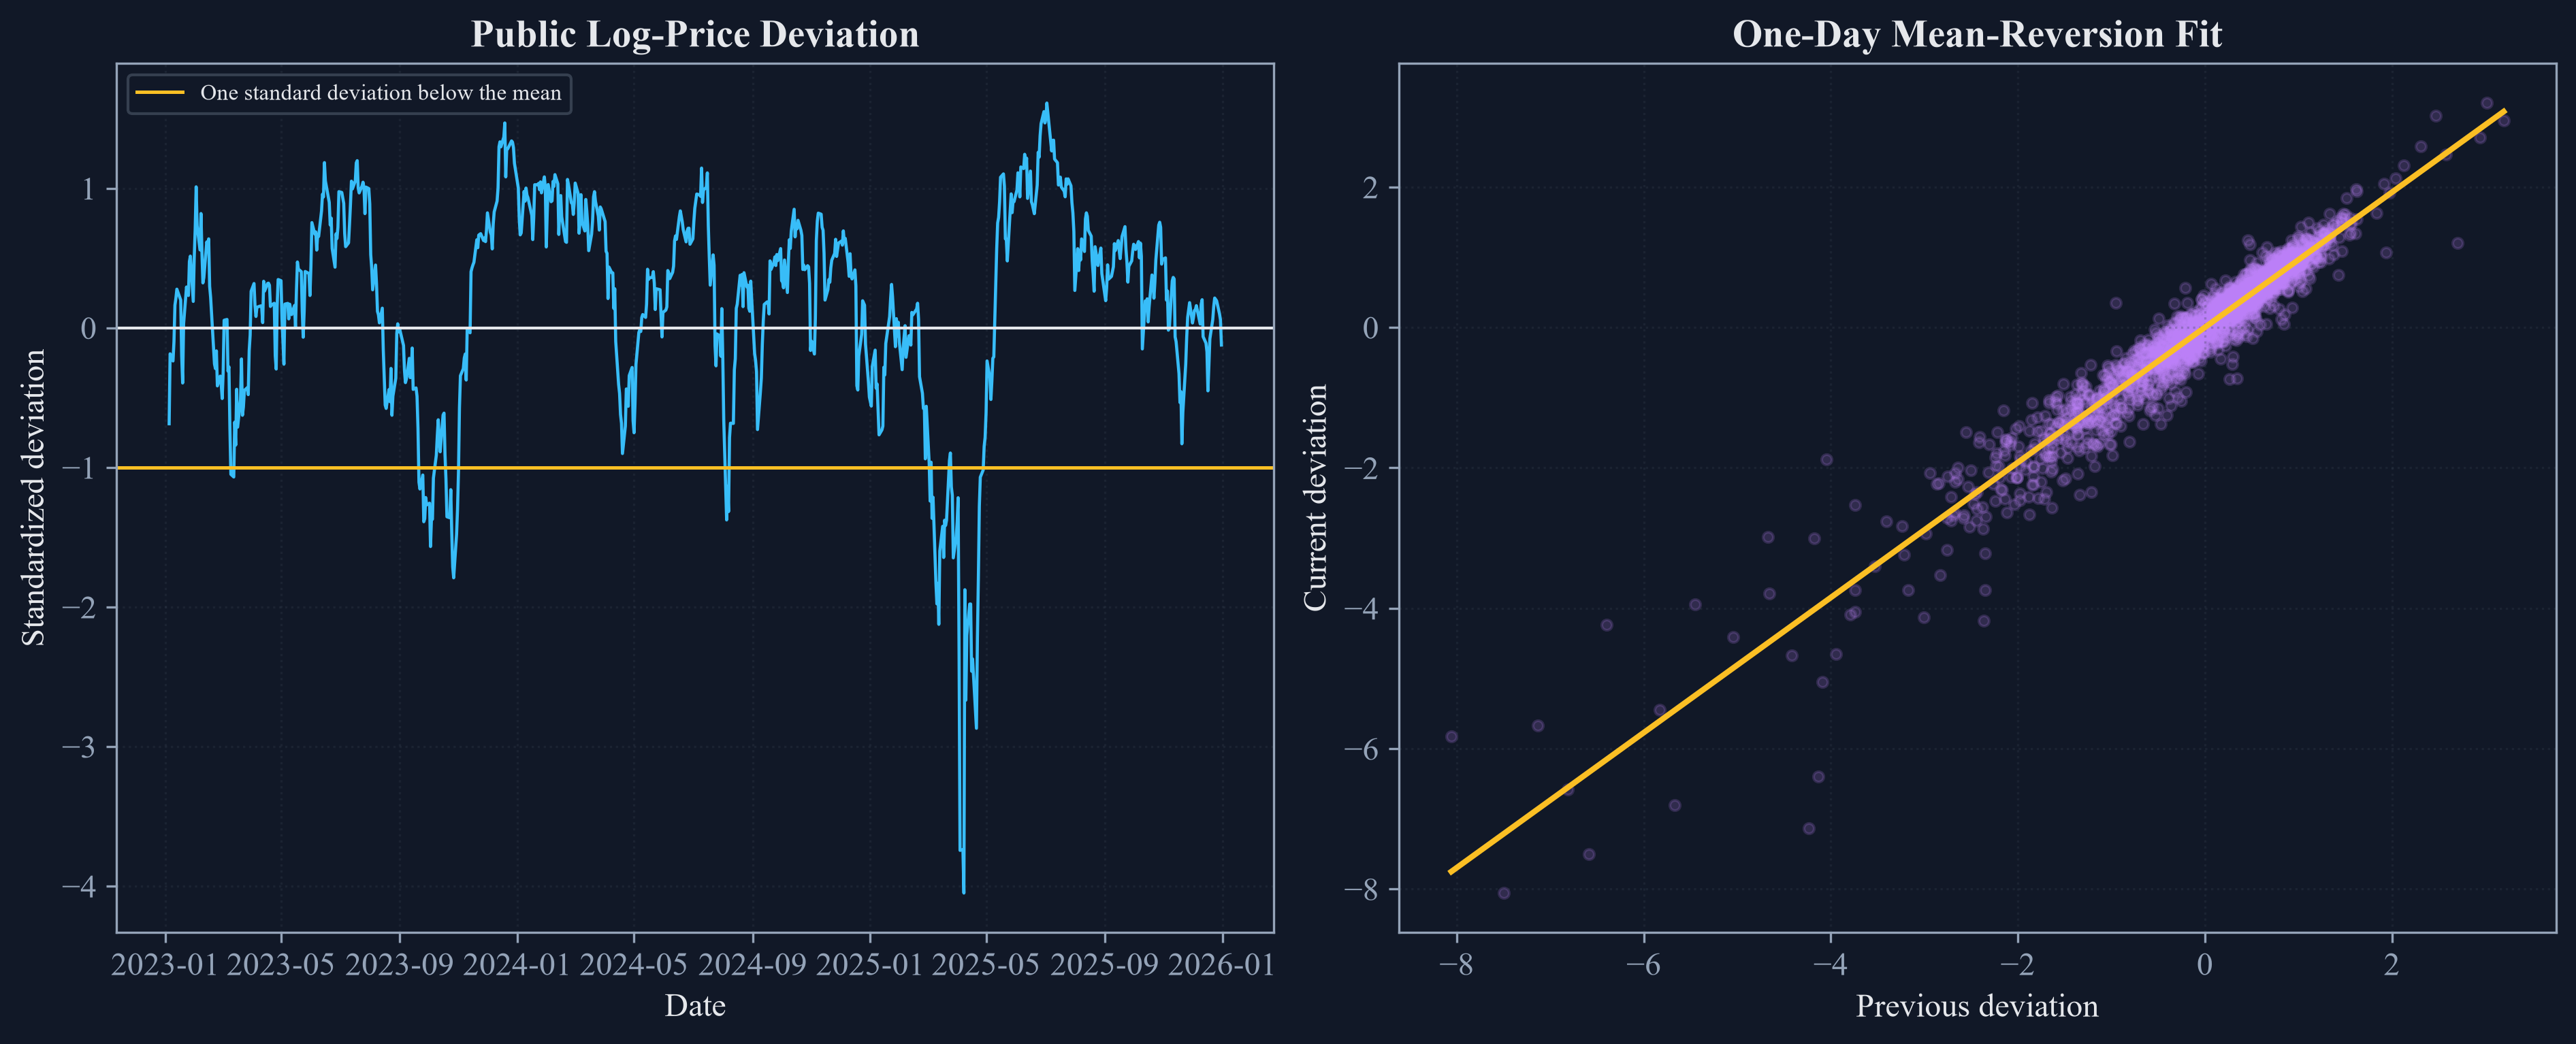

In [2]:
public_fit_table = pd.DataFrame({'Quantity': ['Public observations', 'Deviation observations', 'Rolling mean length', 'Persistence', 'Mean-reversion speed', 'Shock scale', 'Long-run mean', 'Half-life in trading days', 'Stationary standard deviation', 'One-step fit R-squared'], 'Value': [len(prices), len(standardized_deviation), 60, public_fit['rho'], public_fit['theta'], public_fit['sigma'], public_fit['mu'], public_fit['half_life'], public_fit['stationary_std'], public_fit['r2']]})
public_deviation_provenance = pd.DataFrame({'Field': ['Series', 'Provider', 'Source', 'First deviation', 'Last deviation', 'Deviation definition'], 'Value': ['S&P 500', 'Federal Reserve Bank of St. Louis', DATA_URL, str(standardized_deviation.index.min().date()), str(standardized_deviation.index.max().date()), 'Log price minus its sixty-day rolling mean, then standardized']})
save_table(public_deviation_provenance, 'ou_data_provenance', 'Public observations used for the mean-reversion study.', 'tab:chapter19-ou-data')
save_table(public_fit_table, 'public_ou_fit', 'Fitted mean-reversion quantities for the public deviation.', 'tab:chapter19-public-ou-fit', fit=False)
display(public_deviation_provenance)
display(public_fit_table)
lagged = standardized_deviation.shift(1).dropna()
current = standardized_deviation.reindex(lagged.index)
fitted_current = public_fit['mu'] * (1.0 - public_fit['rho']) + public_fit['rho'] * lagged
recent = standardized_deviation.iloc[-750:]
figure, axes = plt.subplots(1, 2, figsize=(12.5, 5.0), constrained_layout=True)
axes[0].plot(recent.index, recent, color=palette['cyan'], linewidth=1.1)
axes[0].axhline(0, color=palette['text'], linewidth=1.0)
axes[0].axhline(-1, color=palette['amber'], linewidth=1.2, label='One standard deviation below the mean')
axes[0].set_title('Public Log-Price Deviation')
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Standardized deviation')
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.28)
axes[1].scatter(lagged, current, color=palette['violet'], alpha=0.18, s=13)
order = np.argsort(lagged.to_numpy())
axes[1].plot(lagged.to_numpy()[order], fitted_current.to_numpy()[order], color=palette['amber'], linewidth=2.0)
axes[1].set_title('One-Day Mean-Reversion Fit')
axes[1].set_xlabel('Previous deviation')
axes[1].set_ylabel('Current deviation')
axes[1].grid(alpha=0.28)
save_figure(figure, 'public_ou_fit')


## Evaluating barriers through exits and holding times

The upper-barrier probability and the expected net return per unit time are:

$$
u(y_0)=\frac{S(y_0)-S(a)}{S(b)-S(a)},
\qquad
S(x)=\int_0^x\exp\!\left(\frac{\theta s^2}{\sigma^2}\right)ds,
\qquad
R=\frac{g_+u-g_-(1-u)-c}{E[\tau]}.
$$

Here, $y_0=-e$ is the entry deviation, $e>0$ is the entry gap below the mean, $a=y_0-g_-$ is the lower barrier, $b=y_0+g_+$ is the upper barrier, $g_+>0$ is the profit amount, $g_->0$ is the loss amount, $S$ is the scale function, $u(y_0)$ is the chance of reaching the upper barrier first, $c\geq0$ is the cost per completed position, $\tau$ is the first exit time, and $R$ is expected net return per unit time.

,Quantity,Value
0,Entry gap,1
1,Cost,0.020000
2,Profit amount,0.273127
3,Loss amount,4
4,Upper-hit probability,0.999993
5,Expected gain,0.253097
6,Gain standard deviation,0.011308
7,Expected holding time,4.983531
8,Expected return per unit time,0.050787
9,Time-scaled Sharpe,10.025966


,Profit amount,Loss amount,Upper-hit probability,Expected holding time,Expected return per unit time
0,0.1,2,0.995442,1.626759,0.043294
1,0.2,2,0.991314,3.345630,0.048090
2,0.3,2,0.987534,5.165069,0.048659
3,0.4,2,0.984036,7.094737,0.048160
4,0.5,2,0.980764,9.145681,0.047226
5,0.6,2,0.977673,11.330563,0.046066
6,0.7,2,0.974721,13.663927,0.044771
7,0.8,2,0.971874,16.162528,0.043387
8,0.9,2,0.969099,18.845725,0.041940
9,1,2,0.966367,21.735957,0.040445


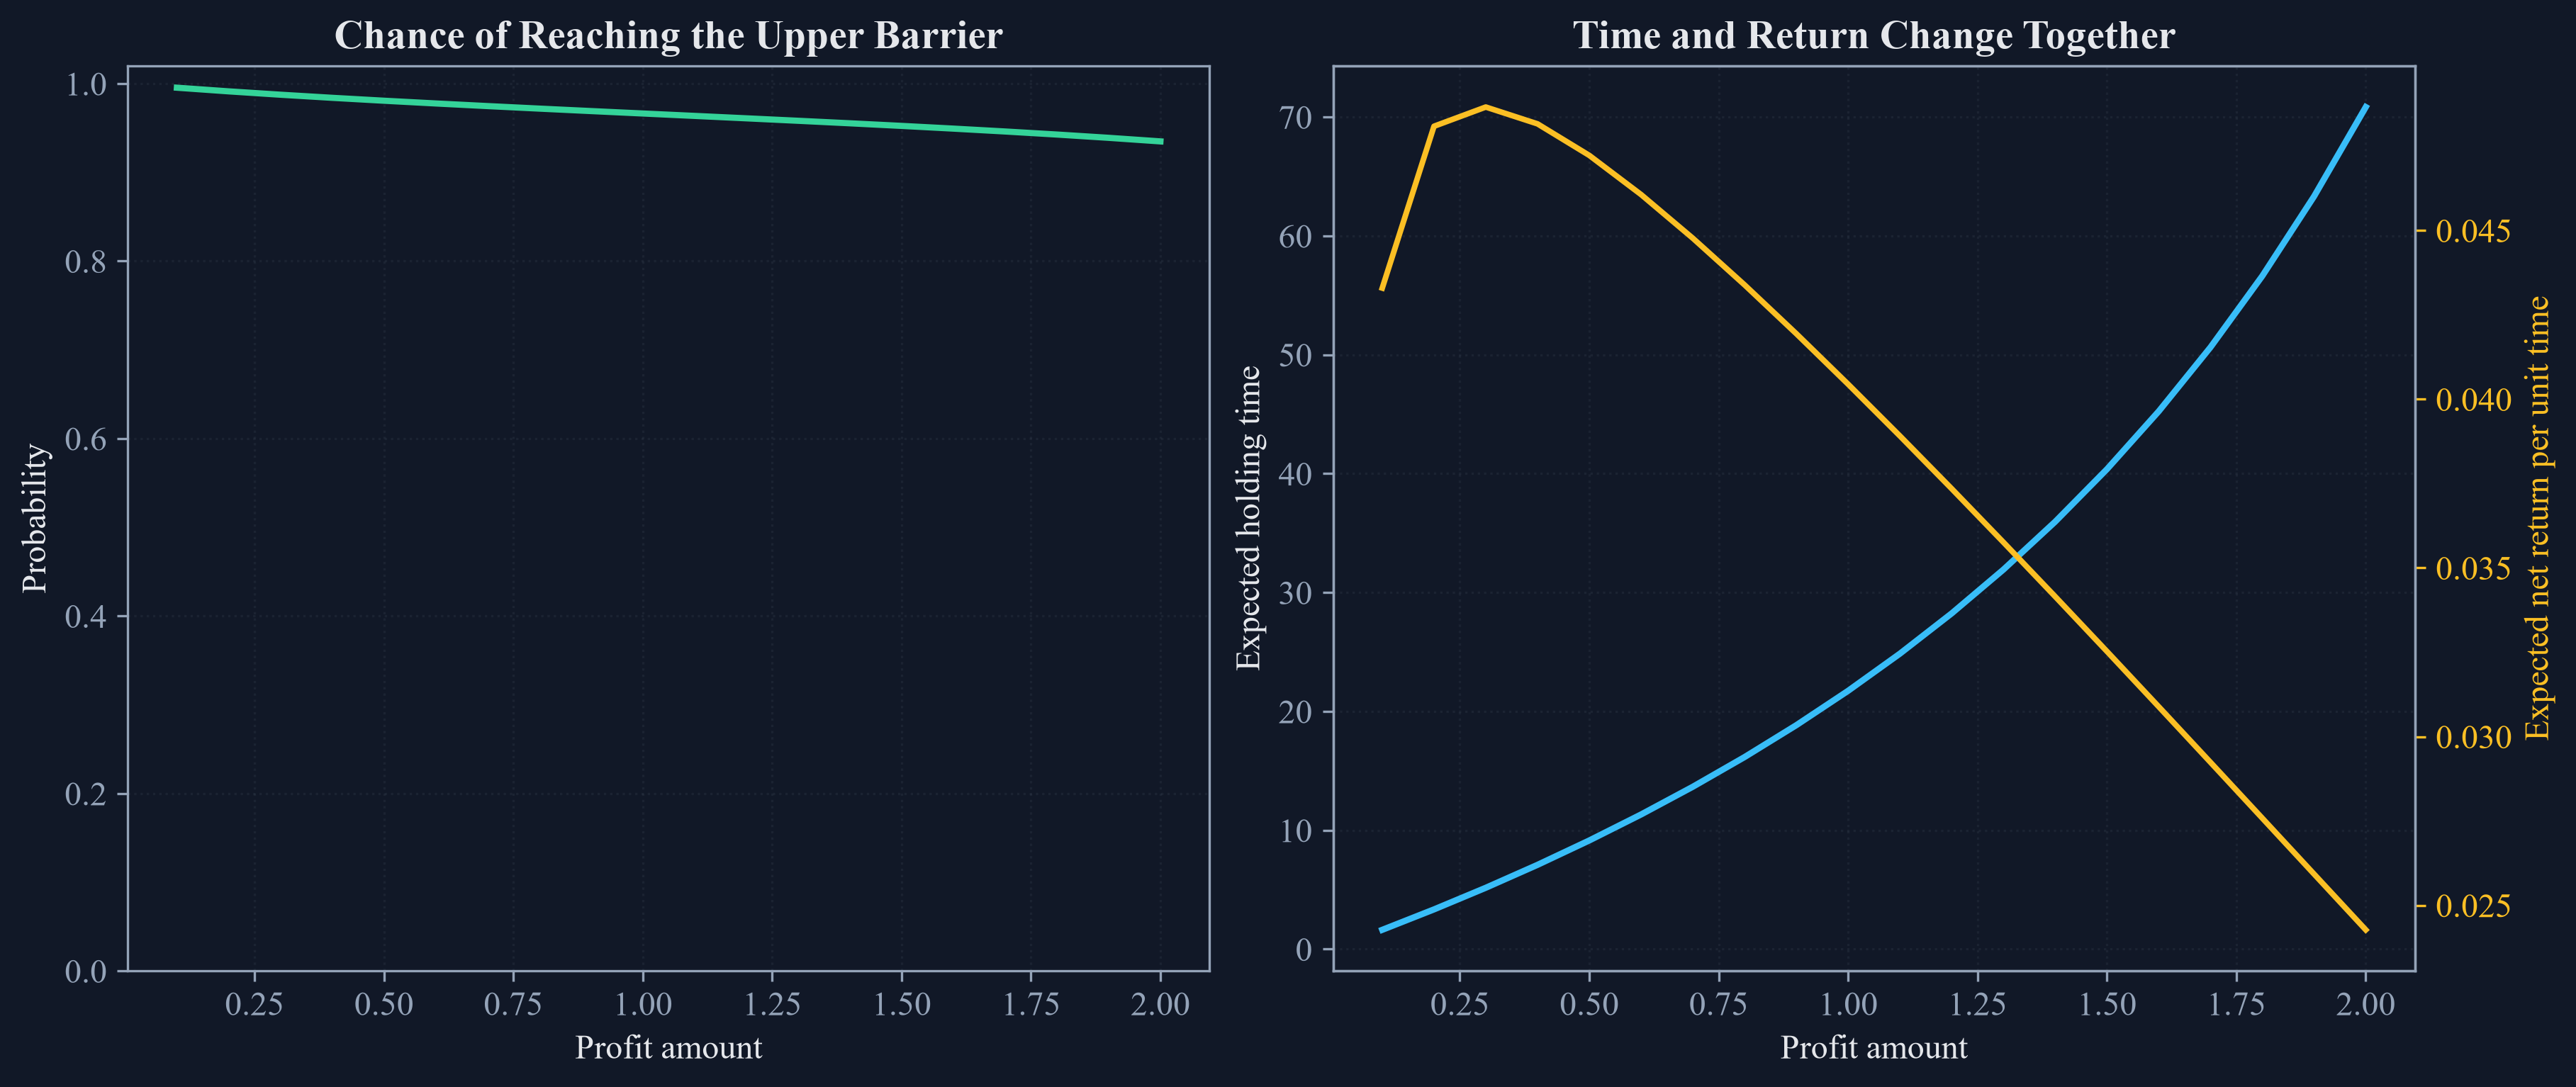

In [3]:
public_entry_gap = 1.0
public_cost = 0.02
public_rule = optimal_ou_trading_rule(public_fit["theta"], public_fit["sigma"], public_entry_gap, cost=public_cost, bounds=(0.10, 4.00))
public_rule_table = pd.DataFrame({
    "Quantity": ["Entry gap", "Cost", "Profit amount", "Loss amount", "Upper-hit probability", "Expected gain", "Gain standard deviation", "Expected holding time", "Expected return per unit time", "Time-scaled Sharpe"],
    "Value": [public_entry_gap, public_cost, public_rule["profit_take"], public_rule["stop_loss"], public_rule["hit_probability"], public_rule["expected_gain"], public_rule["std_gain"], public_rule["expected_holding_time"], public_rule["return_rate"], public_rule["time_scaled_sharpe"]],
})
barrier_rows = []
fixed_stop = 2.0
for profit_take in np.linspace(0.10, 2.00, 20):
    values = ou_rule_metrics(profit_take, fixed_stop, public_fit["theta"], public_fit["sigma"], public_entry_gap, public_cost)
    barrier_rows.append({"Profit amount": profit_take, "Loss amount": fixed_stop, "Upper-hit probability": values["hit_probability"], "Expected holding time": values["expected_holding_time"], "Expected return per unit time": values["return_rate"]})
barrier_sensitivity = pd.DataFrame(barrier_rows)
save_table(public_rule_table, "public_ou_rule", "Illustrative public-data barrier rule within the declared search box.", "tab:chapter19-public-ou-rule", fit=False)
save_table(barrier_sensitivity, "barrier_sensitivity", "Exit probability, holding time, and return rate as the upper barrier changes.", "tab:chapter19-barrier-sensitivity")
display(public_rule_table)
display(barrier_sensitivity)

figure, axes = plt.subplots(1, 2, figsize=(12.0, 5.0), constrained_layout=True)
axes[0].plot(barrier_sensitivity["Profit amount"], barrier_sensitivity["Upper-hit probability"], color=palette["green"], linewidth=2.1)
axes[0].set_title("Chance of Reaching the Upper Barrier")
axes[0].set_xlabel("Profit amount")
axes[0].set_ylabel("Probability")
axes[0].set_ylim(0, 1.02)
axes[0].grid(alpha=0.28)
axes[1].plot(barrier_sensitivity["Profit amount"], barrier_sensitivity["Expected holding time"], color=palette["cyan"], linewidth=2.1, label="Expected holding time")
second_axis = axes[1].twinx()
second_axis.plot(barrier_sensitivity["Profit amount"], barrier_sensitivity["Expected return per unit time"], color=palette["amber"], linewidth=1.9, label="Return rate")
second_axis.tick_params(axis="y", colors=palette["amber"])
second_axis.set_ylabel("Expected net return per unit time", color=palette["amber"])
axes[1].set_title("Time and Return Change Together")
axes[1].set_xlabel("Profit amount")
axes[1].set_ylabel("Expected holding time")
axes[1].grid(alpha=0.28)
save_figure(figure, "barrier_probability_holding")

## Preliminary Monte Carlo Reproduction

Exact daily transitions generate controlled Ornstein-Uhlenbeck paths for the grid comparison:

$$
Y_{t+\Delta}=e^{-\theta\Delta}Y_t+\sigma\sqrt{\frac{1-e^{-2\theta\Delta}}{2\theta}}\,Z_{t+\Delta},
\qquad
Z_{t+\Delta}\overset{iid}{\sim}\mathcal N(0,1).
$$

Here, $\Delta$ is the time step, $e^{-\theta\Delta}$ is the one-step persistence, $Z_{t+\Delta}$ is a new standard normal shock, and the square-root term is the exact innovation scale. The path begins at the declared entry deviation.

,Quantity,Value
0,Paths,8000
1,Steps per path,400
2,Grid points per side,16
3,Grid cells,256
4,Monte Carlo profit amount,0.750000
5,Monte Carlo loss amount,2
6,Monte Carlo return rate,0.044259
7,Analytical profit amount,0.535464
8,Analytical loss amount,4
9,Analytical return rate,0.059772


,Surface,Profit amount,Loss amount,Expected return per unit time
0,Monte Carlo grid,0.750000,2,0.044259
1,Analytical grid,0.500000,4,0.059691
2,Continuous analytical search,0.535464,4,0.059772


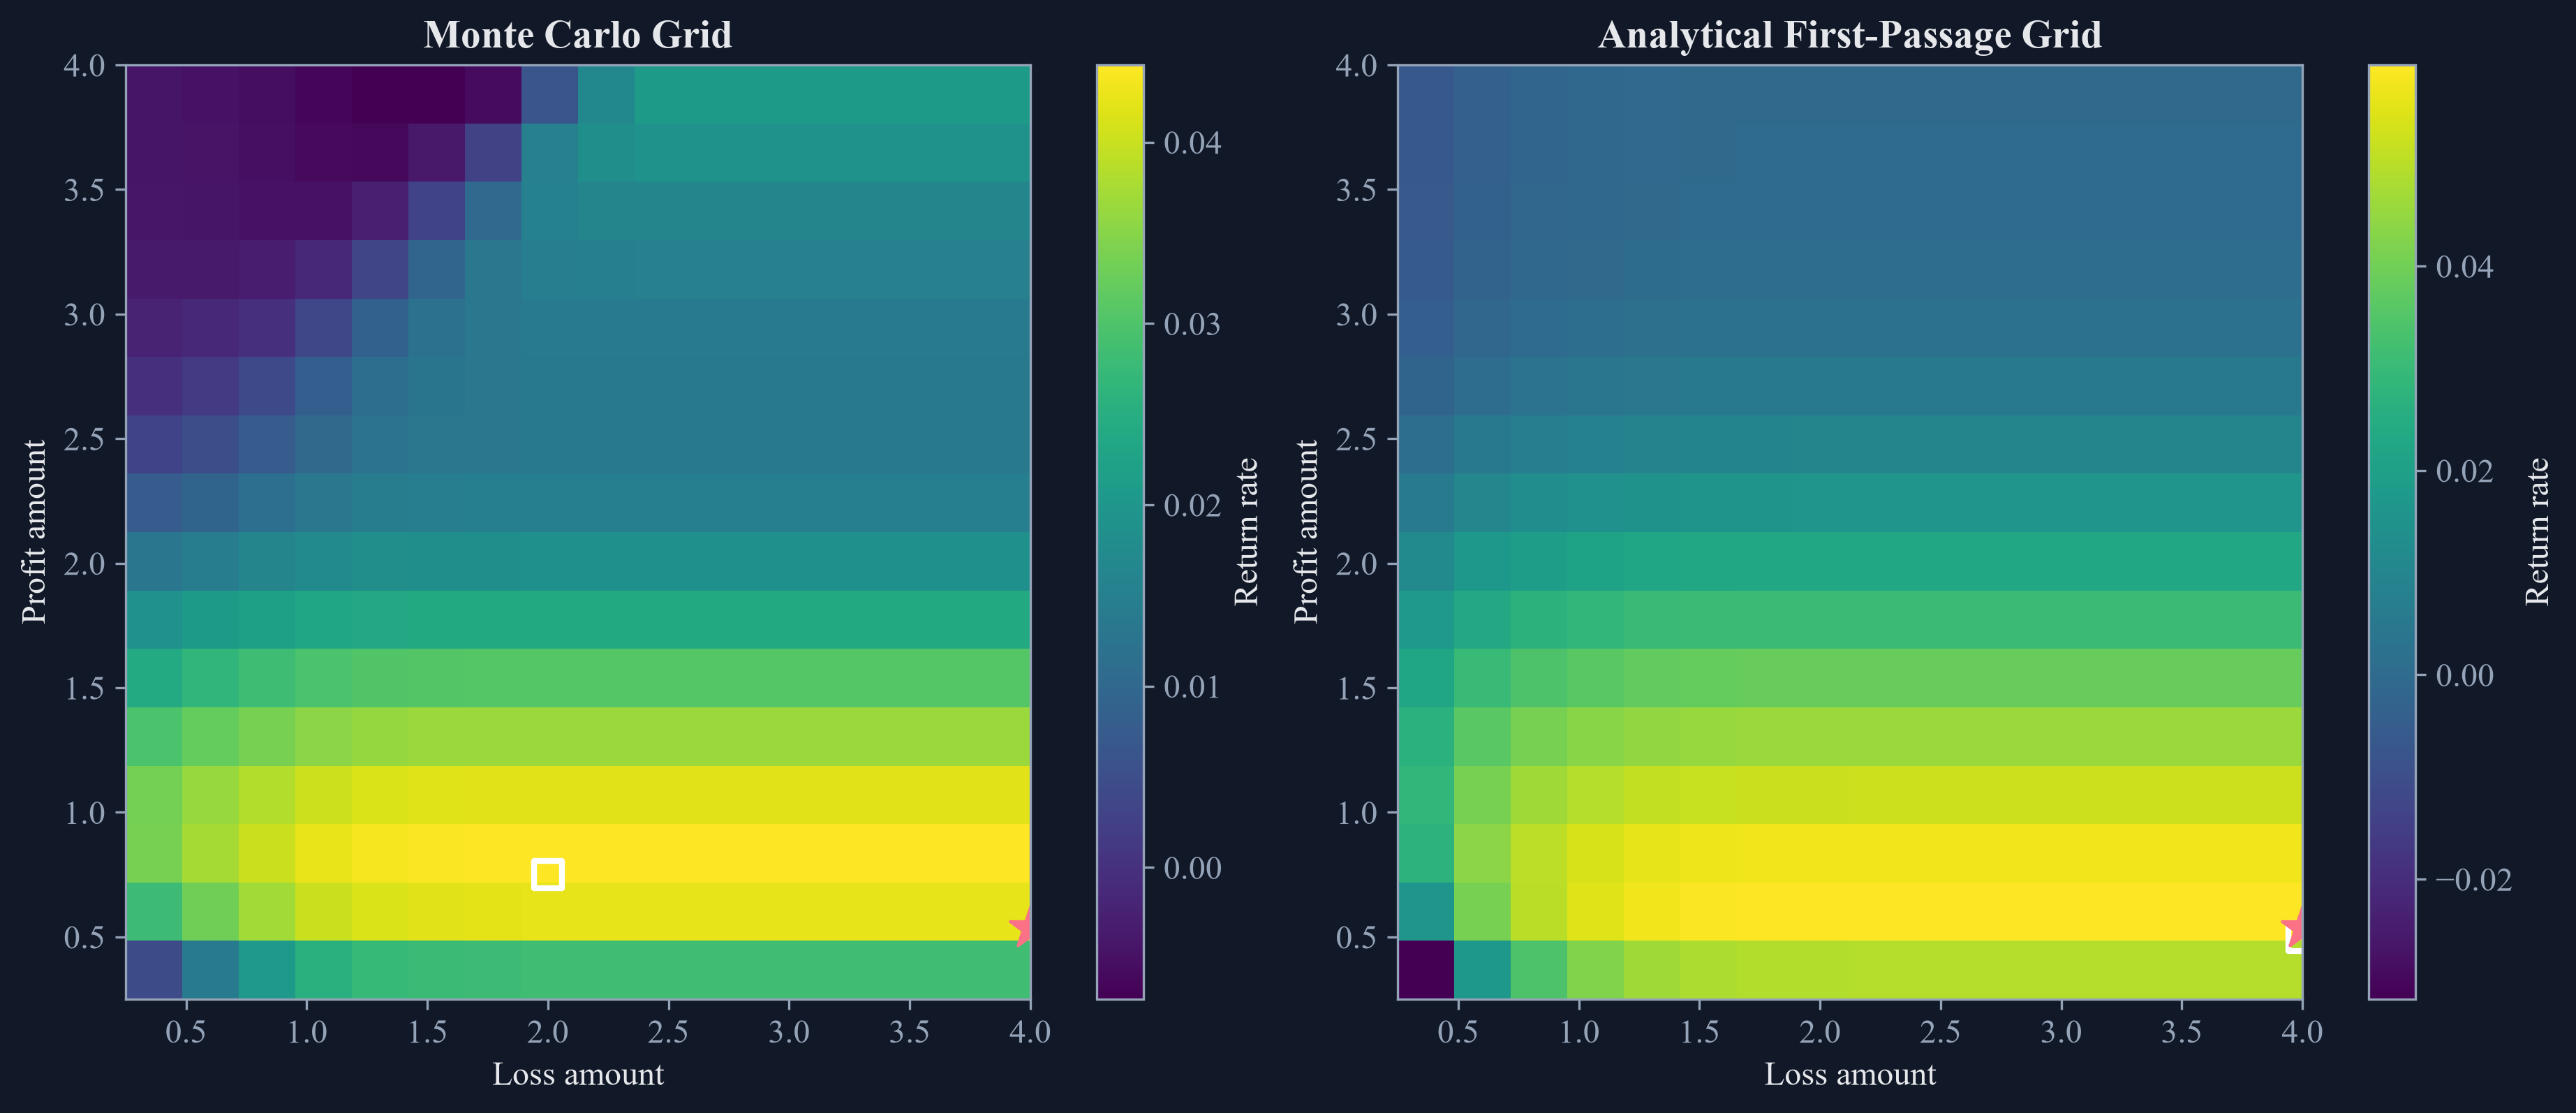

In [4]:
preliminary_theta = theta_from_half_life(10.0)
preliminary_sigma = 0.25
preliminary_entry_gap = 1.0
preliminary_cost = 0.10
preliminary_dt = 1.0
preliminary_rng = np.random.default_rng(0)
preliminary_paths = simulate_ou(preliminary_theta, preliminary_sigma, 8000, 400, preliminary_dt, preliminary_rng, y_start=-preliminary_entry_gap)
preliminary_grid = np.round(np.arange(0.25, 4.01, 0.25), 3)
start_time = time.perf_counter()
monte_carlo_surface = np.array([[monte_carlo_return_rate(preliminary_paths, preliminary_entry_gap, profit_take, stop_loss, preliminary_cost, preliminary_dt) for stop_loss in preliminary_grid] for profit_take in preliminary_grid])
monte_carlo_seconds = time.perf_counter() - start_time
monte_carlo_location = np.unravel_index(np.nanargmax(monte_carlo_surface), monte_carlo_surface.shape)
start_time = time.perf_counter()
repetitions = 50
for repetition in range(repetitions):
    preliminary_rule = optimal_ou_trading_rule(preliminary_theta, preliminary_sigma, preliminary_entry_gap, cost=preliminary_cost, bounds=(0.25, 4.00))
analytical_seconds = (time.perf_counter() - start_time) / repetitions
analytical_surface = np.array([[ou_rule_metrics(profit_take, stop_loss, preliminary_theta, preliminary_sigma, preliminary_entry_gap, preliminary_cost)["return_rate"] for stop_loss in preliminary_grid] for profit_take in preliminary_grid])
analytical_location = np.unravel_index(np.nanargmax(analytical_surface), analytical_surface.shape)
preliminary_reproduction = pd.DataFrame({
    "Quantity": ["Paths", "Steps per path", "Grid points per side", "Grid cells", "Monte Carlo profit amount", "Monte Carlo loss amount", "Monte Carlo return rate", "Analytical profit amount", "Analytical loss amount", "Analytical return rate", "Profit-amount difference", "Grid spacing", "Monte Carlo seconds", "Analytical seconds per fit", "Speed ratio"],
    "Value": [8000, 400, len(preliminary_grid), len(preliminary_grid) ** 2, preliminary_grid[monte_carlo_location[0]], preliminary_grid[monte_carlo_location[1]], monte_carlo_surface[monte_carlo_location], preliminary_rule["profit_take"], preliminary_rule["stop_loss"], preliminary_rule["return_rate"], abs(preliminary_rule["profit_take"] - preliminary_grid[monte_carlo_location[0]]), 0.25, monte_carlo_seconds, analytical_seconds, monte_carlo_seconds / analytical_seconds],
})
exact_grid_best = pd.DataFrame({
    "Surface": ["Monte Carlo grid", "Analytical grid", "Continuous analytical search"],
    "Profit amount": [preliminary_grid[monte_carlo_location[0]], preliminary_grid[analytical_location[0]], preliminary_rule["profit_take"]],
    "Loss amount": [preliminary_grid[monte_carlo_location[1]], preliminary_grid[analytical_location[1]], preliminary_rule["stop_loss"]],
    "Expected return per unit time": [monte_carlo_surface[monte_carlo_location], analytical_surface[analytical_location], preliminary_rule["return_rate"]],
})
save_table(preliminary_reproduction, "preliminary_ou_reproduction", "Reproduction of the preliminary Monte Carlo and analytical barrier comparison.", "tab:chapter19-preliminary-ou", fit=False)
save_table(exact_grid_best, "ou_grid_best", "Best barrier pair on each controlled surface.", "tab:chapter19-ou-grid-best")
display(preliminary_reproduction)
display(exact_grid_best)

extent = [preliminary_grid[0], preliminary_grid[-1], preliminary_grid[0], preliminary_grid[-1]]
figure, axes = plt.subplots(1, 2, figsize=(12.2, 5.2), constrained_layout=True)
first_image = axes[0].imshow(monte_carlo_surface, origin="lower", aspect="auto", cmap="viridis", extent=extent)
axes[0].scatter([preliminary_grid[monte_carlo_location[1]]], [preliminary_grid[monte_carlo_location[0]]], marker="s", s=90, edgecolor="white", facecolor="none", linewidth=2)
axes[0].scatter([preliminary_rule["stop_loss"]], [preliminary_rule["profit_take"]], marker="*", s=220, color=palette["rose"])
axes[0].set_title("Monte Carlo Grid")
axes[0].set_xlabel("Loss amount")
axes[0].set_ylabel("Profit amount")
figure.colorbar(first_image, ax=axes[0], label="Return rate")
second_image = axes[1].imshow(analytical_surface, origin="lower", aspect="auto", cmap="viridis", extent=extent)
axes[1].scatter([preliminary_grid[analytical_location[1]]], [preliminary_grid[analytical_location[0]]], marker="s", s=90, edgecolor="white", facecolor="none", linewidth=2)
axes[1].scatter([preliminary_rule["stop_loss"]], [preliminary_rule["profit_take"]], marker="*", s=220, color=palette["rose"])
axes[1].set_title("Analytical First-Passage Grid")
axes[1].set_xlabel("Loss amount")
axes[1].set_ylabel("Profit amount")
figure.colorbar(second_image, ax=axes[1], label="Return rate")
save_figure(figure, "ou_surface_comparison")

## Searching for barriers after costs

The barrier pair is chosen inside an explicitly bounded search region:

$$
(g_+^*,g_-^*)=\arg\max_{\ell\leq g_+,g_-\leq u}R(g_+,g_-;\theta,\sigma,e,c).
$$

Here, $R$ is the expected net return per unit time, $g_+$ and $g_-$ are the profit and loss amounts, $\theta$ and $\sigma$ describe the fitted process, $e$ is the entry gap, $c$ is the cost, and $[\ell,u]$ is the declared search interval. A selected value at $\ell$ or $u$ is evidence that the search boundary matters.

,Cost,Profit amount,Loss amount,Upper-hit probability,Expected holding time,Expected return per unit time,Touches search boundary
0,0,0.100000,4,0.999997,1.738143,0.057526,True
1,0.01,0.193696,4,0.999995,3.455068,0.053161,True
2,0.02,0.273127,4,0.999993,4.983531,0.050787,True
3,0.05,0.429458,4,0.999990,8.209615,0.046216,True
4,0.10,0.603826,4,0.999986,12.200123,0.041292,True
5,0.20,0.847750,4,0.999982,18.636879,0.034752,True


,Upper search bound,Profit amount,Loss amount,Expected return per unit time,Loss amount at upper bound
0,2,0.286251,2,0.048669,True
1,3,0.273986,3,0.050640,True
2,4,0.273127,4,0.050787,True
3,5,0.273109,5,0.050790,True


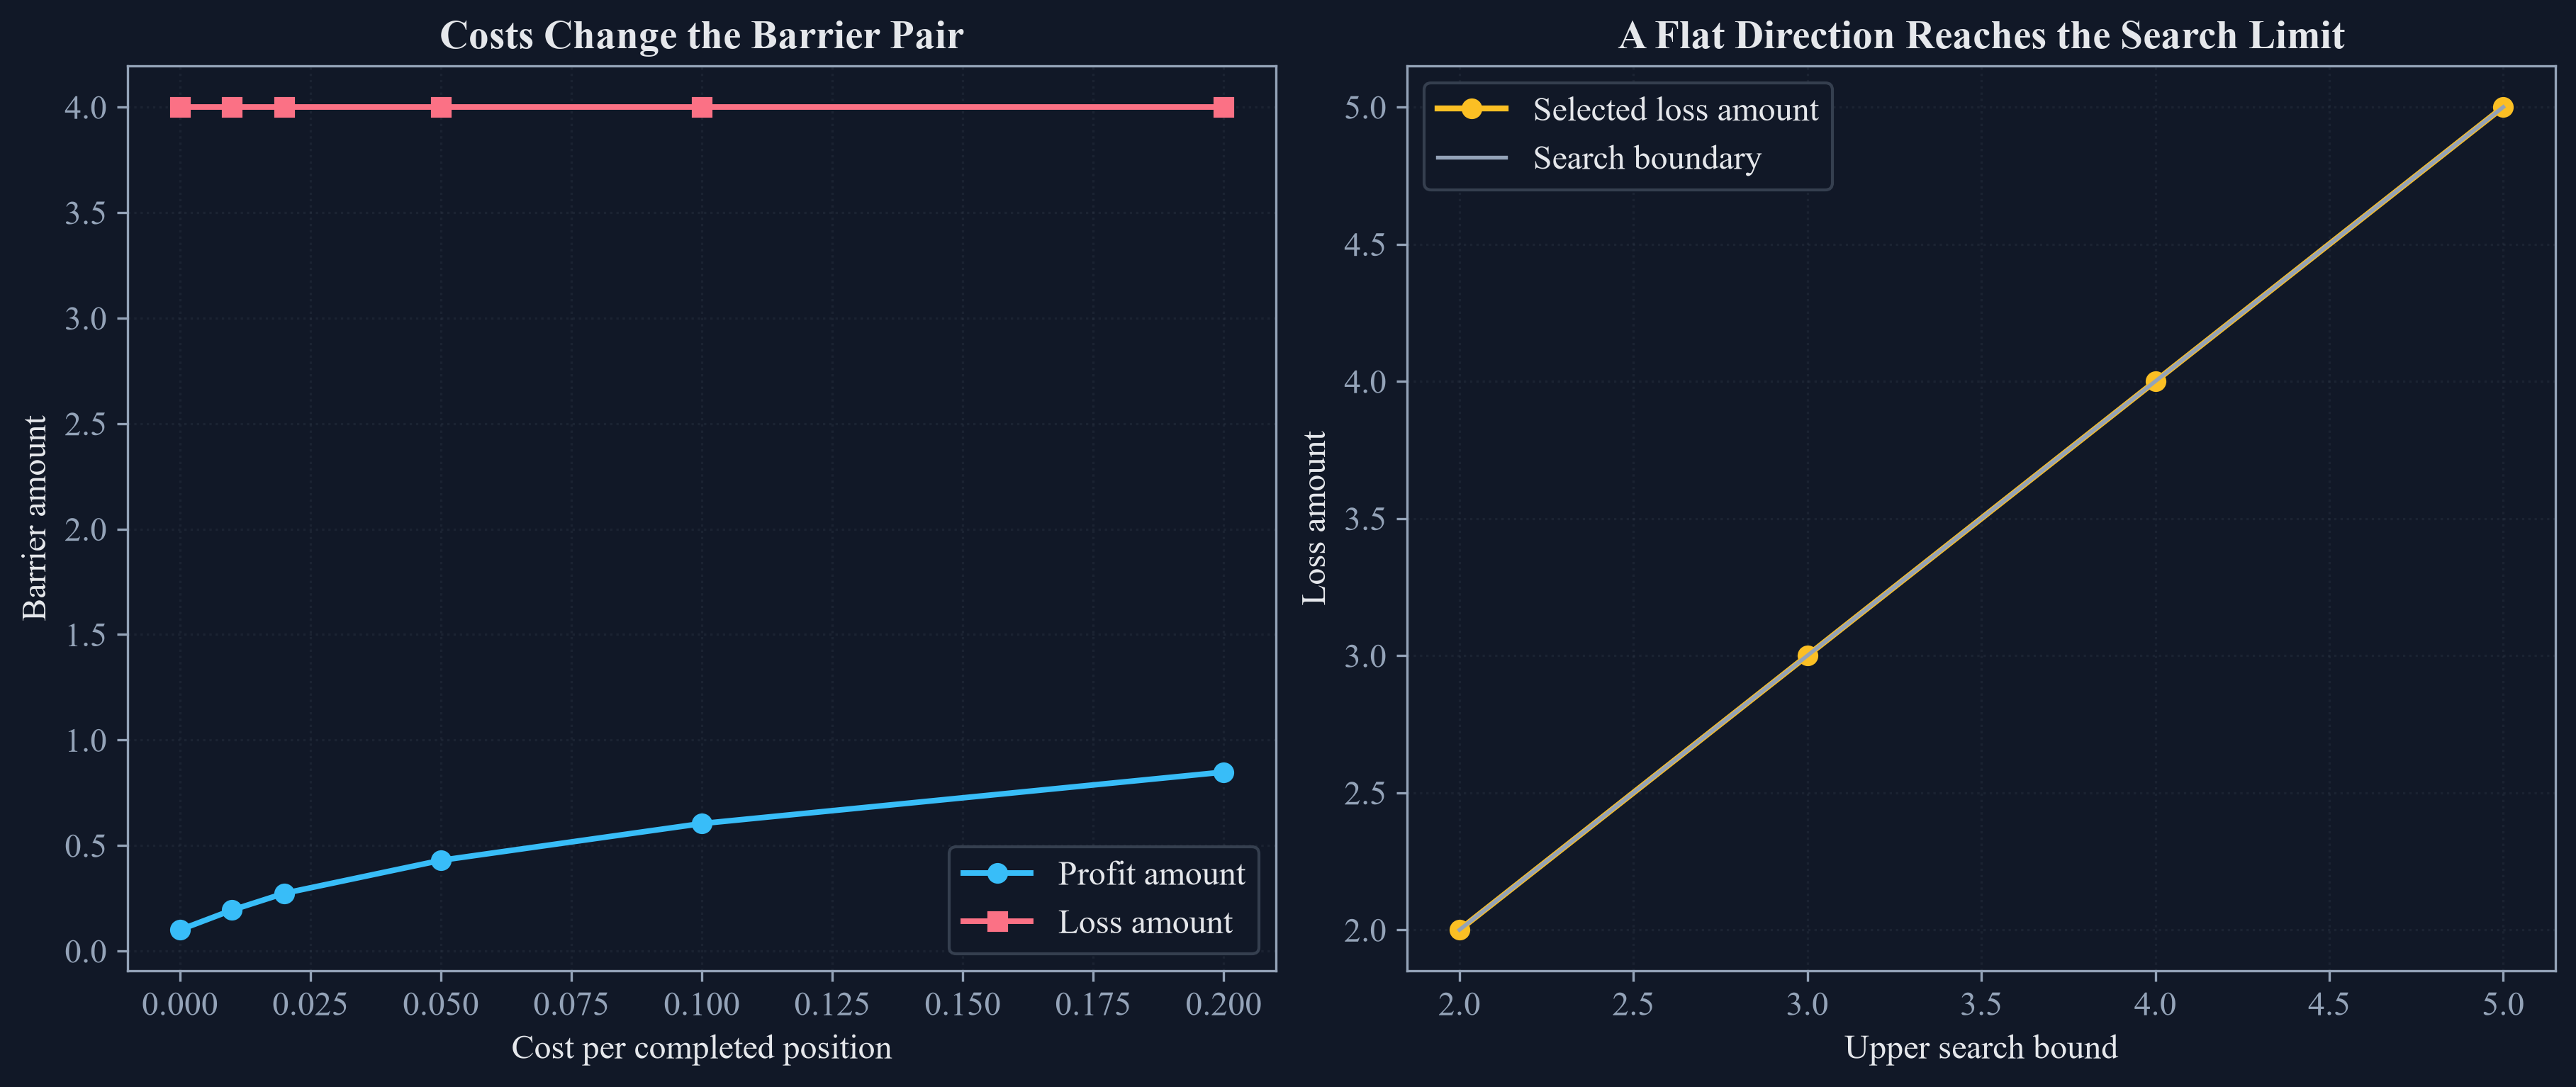

In [5]:
cost_rows = []
for cost in [0.00, 0.01, 0.02, 0.05, 0.10, 0.20]:
    rule = optimal_ou_trading_rule(public_fit["theta"], public_fit["sigma"], public_entry_gap, cost=cost, bounds=(0.10, 4.00))
    cost_rows.append({"Cost": cost, "Profit amount": rule["profit_take"], "Loss amount": rule["stop_loss"], "Upper-hit probability": rule["hit_probability"], "Expected holding time": rule["expected_holding_time"], "Expected return per unit time": rule["return_rate"], "Touches search boundary": bool(np.isclose(rule["profit_take"], 0.10, atol=1e-4) or np.isclose(rule["profit_take"], 4.00, atol=1e-4) or np.isclose(rule["stop_loss"], 0.10, atol=1e-4) or np.isclose(rule["stop_loss"], 4.00, atol=1e-4))})
cost_sensitivity = pd.DataFrame(cost_rows)
boundary_rows = []
for upper_bound in [2.0, 3.0, 4.0, 5.0]:
    rule = optimal_ou_trading_rule(public_fit["theta"], public_fit["sigma"], public_entry_gap, cost=public_cost, bounds=(0.10, upper_bound))
    boundary_rows.append({"Upper search bound": upper_bound, "Profit amount": rule["profit_take"], "Loss amount": rule["stop_loss"], "Expected return per unit time": rule["return_rate"], "Loss amount at upper bound": bool(np.isclose(rule["stop_loss"], upper_bound, atol=1e-4))})
boundary_sensitivity = pd.DataFrame(boundary_rows)
save_table(cost_sensitivity, "ou_cost_sensitivity", "Public-data barrier choices as the cost changes.", "tab:chapter19-ou-cost")
save_table(boundary_sensitivity, "ou_boundary_sensitivity", "Public-data choices under different search limits.", "tab:chapter19-ou-boundary")
display(cost_sensitivity)
display(boundary_sensitivity)

figure, axes = plt.subplots(1, 2, figsize=(12.0, 5.0), constrained_layout=True)
axes[0].plot(cost_sensitivity["Cost"], cost_sensitivity["Profit amount"], marker="o", color=palette["cyan"], linewidth=1.9, label="Profit amount")
axes[0].plot(cost_sensitivity["Cost"], cost_sensitivity["Loss amount"], marker="s", color=palette["rose"], linewidth=1.9, label="Loss amount")
axes[0].set_title("Costs Change the Barrier Pair")
axes[0].set_xlabel("Cost per completed position")
axes[0].set_ylabel("Barrier amount")
axes[0].legend()
axes[0].grid(alpha=0.28)
axes[1].plot(boundary_sensitivity["Upper search bound"], boundary_sensitivity["Loss amount"], marker="o", color=palette["amber"], linewidth=2.0, label="Selected loss amount")
axes[1].plot(boundary_sensitivity["Upper search bound"], boundary_sensitivity["Upper search bound"], color=palette["muted"], linewidth=1.3, label="Search boundary")
axes[1].set_title("A Flat Direction Reaches the Search Limit")
axes[1].set_xlabel("Upper search bound")
axes[1].set_ylabel("Loss amount")
axes[1].legend()
axes[1].grid(alpha=0.28)
save_figure(figure, "ou_cost_boundary_sensitivity")

## Tests

In [6]:
assert len(prices) == 2330
assert len(standardized_deviation) == 2271
assert public_fit['theta'] > 0
assert public_fit['sigma'] > 0
assert 0 < public_fit['rho'] < 1
assert 0 <= public_fit['r2'] <= 1
assert np.isclose(public_fit['stationary_std'], 1.0, atol=0.02)
controlled_probability = hit_upper_probability(1.0, 0.5, 0.5, 0.1, 0.1)
controlled_time = mean_exit_time(1.0, 0.5, 0.5, 0.1, 0.1)
assert 0.5 < controlled_probability <= 1.0
assert controlled_time > 0 and np.isfinite(controlled_time)
assert preliminary_reproduction.shape == (15, 2)
assert abs(preliminary_rule['profit_take'] - preliminary_grid[monte_carlo_location[0]]) <= 0.25 + 1e-09
assert preliminary_rule['return_rate'] >= analytical_surface[analytical_location] - 0.001
assert ou_rule_metrics(0.0, 0.5, 0.1, 0.1, 1.0)['return_rate'] == -np.inf
assert ou_rule_metrics(0.5, -0.1, 0.1, 0.1, 1.0)['return_rate'] == -np.inf
recovery_rng = np.random.default_rng(5)
recovery_theta = theta_from_half_life(20.0)
recovery_path = simulate_ou(recovery_theta, 0.1, 1, 6000, 1.0, recovery_rng).ravel()
recovery_fit = fit_ornstein_uhlenbeck(recovery_path)
assert abs(recovery_fit['half_life'] - 20.0) < 6.0
assert cost_sensitivity['Expected return per unit time'].is_monotonic_decreasing
assert int(boundary_sensitivity['Loss amount at upper bound'].sum()) == 4
assert (FIGURES / 'public_ou_fit.pdf').exists()
assert (FIGURES / 'barrier_probability_holding.pdf').exists()
assert (FIGURES / 'ou_surface_comparison.pdf').exists()
assert (FIGURES / 'ou_cost_boundary_sensitivity.pdf').exists()
check_summary = pd.DataFrame({'Check': ['Public file identity', 'Mean-reversion fit', 'Probability bounds', 'Positive holding time', 'Monte Carlo grid agreement', 'Analytical grid agreement', 'Known half-life recovery', 'Cost direction', 'Boundary contact'], 'Status': ['Pass'] * 9})
display(check_summary)


,Check,Status
0,Public file identity,Pass
1,Mean-reversion fit,Pass
2,Probability bounds,Pass
3,Positive holding time,Pass
4,Monte Carlo grid agreement,Pass
5,Analytical grid agreement,Pass
6,Known half-life recovery,Pass
7,Cost direction,Pass
8,Boundary contact,Pass
